<a href="https://colab.research.google.com/github/paulacoronel0/AprendizajeProfundo/blob/main/Actividad5_Fine-Tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Actividad 5: Fine-tuning supervisado**

**Integrantes:**
* Coronel, Paula Martina FAI-3813
* Villarroel, Valentina FAI-3944

## **Actividad 1. Reproducción y comprensión del tutorial**

A continuación respondemos las consignas basadas en el tutorial de clasificación de imágenes de hot dogs y no hot dogs [Notebook HotDogs con FineTunning](https://colab.research.google.com/github/institutohumai/cursos-python/blob/master/CV/4_Transfer_Learning/2_FineTuning.ipynb):

1. ¿Qué problema se intenta resolver y cuáles son las clases que debe reconocer el
modelo?

    El modelo intanta resolver un problema de clasificación de imagenes para distingir si es una imagen es un hot dog o no. Es decir, que como clases tenemos dos: "hot dog" (clase positiva) y "not-hotdog" (clase negativa).

2. ¿Qué conjunto de datos se utiliza? Indicar la cantidad de imágenes de entrenamiento
y de prueba.

    Se utiliza un conjunto de datos de imágenes recopiladas de internet. Cuenta con 1000 imágenes de entrenamiento por clase (2000 en total) y las restantes se utilizan para pruebas (400 por clase, 800 en total).

3. ¿Qué es ImageNet y qué significa que ResNet-18 esté preentrenada con ese conjunto
de datos?

    ImageNet es un conjunto de datos a gran escala con más de 10 millones de imágenes y 1000 clases distintas. Que ResNet-18 esté preentrenada significa que sus parámetros ya fueron ajustados previamente con ImageNet, aprendiendo a extraer características visuales generales como bordes, texturas y formas.   

4. ¿Cuál es la arquitectura utilizada? Identificar las principales partes de ResNet-18 y
explicar cuál es la función de la capa final.

    La arquitectura base es ResNet-18, esta conformada por varias capas de extracción de características y una capa final de salida (capa densa o fc). La función de esta capa final original es transformar los resultados de la capa de pooling global en 1000 probabilidades correspondientes a las clases de ImageNet.


5. ¿Por qué se reemplaza la capa de salida original del modelo? ¿Qué diferencia existe
entre la cantidad de salidas de la red original y la nueva?

    Se reemplaza porque la tarea original predecía 1000 categorías, pero el nuevo conjunto de datos de destino requiere una predicción binaria, es decir, que la red nueva tiene únicamente 2 salidas.


6. ¿Qué transformaciones se aplican a las imágenes antes de ingresarlas a la red? Ex-
plicar la finalidad de las transformaciones utilizadas durante el entrenamiento y
durante la prueba.

    Durante el entrenamiento se aplican recortes aleatorios de tamaño y relación de aspecto variables, también giros horizontales aleatorios (RandomResizedCrop y RandomHorizontalFlip) con el fin de aumentar artificialmente los datos y evitar el sobreajuste. Durante las pruebas, las imágenes solo se redimensionan y se recortan al centro (CenterCrop) porque el objetivo es evaluar la imagen real estandarizada sin añadir ruido o variaciones. En ambas etapas se estandarizan los canales RGB.


7. ¿Qué significa realizar Fine-Tuning? Explicar qué parámetros del modelo se utilizan
como punto de partida y cuáles deben aprenderse para la nueva tarea.

    Realizar Fine-Tuning es transferir el conocimiento de un modelo origen a uno de destino ajustando sutilmente sus pesos. Se toman como punto de partida todos los parámetros de las capas de características de la red preentrenada, y únicamente los parámetros de la nueva capa de salida se inicializan al azar y se aprenden desde cero.


8. ¿Qué función cumple la tasa de aprendizaje (learning rate)? ¿Por qué en el tutorial
se utiliza una tasa de aprendizaje diferente para la capa de salida?

    La tasa de aprendizaje (learning rate) controla la magnitud de los ajustes en los parámetros durante el entrenamiento. Se utiliza una tasa base pequeña para conservar y "afinar" el conocimiento de las capas preentrenadas, pero se usa una tasa 10 veces mayor para la capa de salida porque sus parámetros se inicializaron al azar y requieren aprender la nueva clasificación desde cero.

9. El tutorial también entrena una red ResNet-18 desde cero. ¿Qué diferencia existe
entre este procedimiento y utilizar una red preentrenada?

    Entrenar desde cero implica inicializar todos los parámetros del modelo con valores aleatorios, requiriendo que la red aprenda todas las representaciones visuales (desde bordes hasta formas) utilizando una tasa de aprendizaje mayor. Utilizar una red preentrenada reutiliza características visuales ya consolidadas, lo cual consume mucho menos recursos.

10. Comparar los resultados de ambos modelos. ¿Qué ventajas se observan al utilizar
los parámetros aprendidos previamente?

    El modelo ajustado con Fine-Tuning obtiene mejores resultados de rendimiento en la misma cantidad de épocas. La principal ventaja es que los valores iniciales de los parámetros preentrenados son altamente efectivos, lo que permite lograr una alta precisión rápidamente y con un conjunto de datos mucho más pequeño.


## **1.1 Reproducción del experimento de hot dogs**

En esta sección se reproduce el tutorial proporcionado por la cátedra.
1. **Lectura del Dataset:** Descarga y extracción de las imágenes.
2. **Data Augmentation:** Aplicación de `RandomResizedCrop` y `RandomHorizontalFlip` para entrenamiento, y `CenterCrop` para evaluación.
3. **Definición e Inicialización:** Carga de **ResNet-18 preentrenada** en ImageNet y adaptación de la última capa (`fc`).
4. **Fine-Tuning:** Entrenamiento ajustando los pesos con una tasa de aprendizaje diferencial.

In [ ]:
%matplotlib inline
import os
import torch
import torchvision
from torch import nn

### 1.1.1 Lectura del dataset

In [ ]:
import requests
import zipfile
import tarfile
url = "http://d2l-data.s3-accelerate.amazonaws.com/hotdog.zip"
os.makedirs("data", exist_ok=True)
fname = os.path.join("data", url.split('/')[-1])
print(f'Downloading {fname} from {url}...')
r = requests.get(url, stream=True, verify=True)
with open(fname, 'wb') as f:
    f.write(r.content)
base_dir = os.path.dirname(fname)
data_dir, ext = os.path.splitext(fname)
if ext == '.zip':
    fp = zipfile.ZipFile(fname, 'r')
elif ext in ('.tar', '.gz'):
    fp = tarfile.open(fname, 'r')
else:
    assert False, 'Only zip/tar files can be extracted.'
fp.extractall(base_dir)




Creamos dos instancias para leer todos los archivos de imagen en el conjunto de datos de entrenamiento y prueba, respectivamente.

In [ ]:
train_imgs = torchvision.datasets.ImageFolder(os.path.join(data_dir, 'train'))
test_imgs = torchvision.datasets.ImageFolder(os.path.join(data_dir, 'test'))

Los primeros 8 ejemplos positivos y las últimas 8 imágenes negativas se muestran a continuación.

In [ ]:
from matplotlib import pyplot as plt
def show_images(imgs, num_rows, num_cols, titles=None, scale=1.5):
    """Plot a list of images.

    Defined in :numref:`sec_utils`"""
    figsize = (num_cols * scale, num_rows * scale)
    _, axes = plt.subplots(num_rows, num_cols, figsize=figsize)
    axes = axes.flatten()
    for i, (ax, img) in enumerate(zip(axes, imgs)):
        try:
            img = img.detach().numpy()
        except:
            pass
        ax.imshow(img)
        ax.axes.get_xaxis().set_visible(False)
        ax.axes.get_yaxis().set_visible(False)
        if titles:
            ax.set_title(titles[i])
    return axes

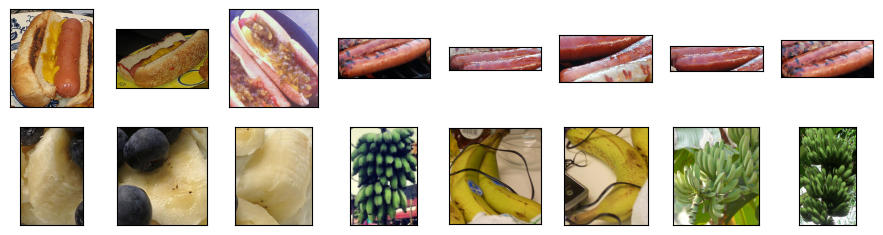

In [ ]:
hotdogs = [train_imgs[i][0] for i in range(8)]
not_hotdogs = [train_imgs[-i - 1][0] for i in range(8)]
show_images(hotdogs + not_hotdogs, 2, 8, scale=1.4);

### 1.1.2 Data Augmentation

In [ ]:
# Specify the means and standard deviations of the three RGB channels to
# standardize each channel
normalize = torchvision.transforms.Normalize(
    [0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

train_augs = torchvision.transforms.Compose([
    torchvision.transforms.RandomResizedCrop(224),
    torchvision.transforms.RandomHorizontalFlip(),
    torchvision.transforms.ToTensor(),
    normalize])

test_augs = torchvision.transforms.Compose([
    torchvision.transforms.Resize(256),
    torchvision.transforms.CenterCrop(224),
    torchvision.transforms.ToTensor(),
    normalize])

NameError: name 'torchvision' is not defined

### 1.1.3 Definición e inicialización del modelo


In [ ]:
pretrained_net = torchvision.models.resnet18(pretrained=True)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 176MB/s]


In [ ]:
pretrained_net.fc

Linear(in_features=512, out_features=1000, bias=True)

In [ ]:
finetune_net = torchvision.models.resnet18(pretrained=True)
finetune_net.fc = nn.Linear(finetune_net.fc.in_features, 2)
nn.init.xavier_uniform_(finetune_net.fc.weight);

### 1.1.4 Haciendo el Fine-Tuning del modelo

In [ ]:
# Si `param_group=True`, los parámetros del modelo en la capa de salida se
# actualizarán usando una tasa de aprendizaje diez veces mayor
def train_fine_tuning(model, learning_rate, batch_size=128, num_epochs=5,
                      param_group=True):
    train_iter = torch.utils.data.DataLoader(torchvision.datasets.ImageFolder(
        os.path.join(data_dir, 'train'), transform=train_augs),
        batch_size=batch_size, shuffle=True)
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    loss = nn.CrossEntropyLoss(reduction="none")
    if param_group:
        params_1x = [param for name, param in model.named_parameters()
             if name not in ["fc.weight", "fc.bias"]]
        trainer = torch.optim.SGD([{'params': params_1x},
                                   {'params': model.fc.parameters(),
                                    'lr': learning_rate * 10}],
                                lr=learning_rate, weight_decay=0.001)
    else:
        trainer = torch.optim.SGD(model.parameters(), lr=learning_rate,
                                  weight_decay=0.001)
    model.to(device)
    for epoch in range(num_epochs):
      L = 0.0
      N = 0
      Acc = 0.0
      for X, y in train_iter:
          X, y = X.to(device), y.to(device)
          l = loss(model(X),y)
          trainer.zero_grad()
          l.sum().backward()
          trainer.step()
          L += l.sum()
          N += l.numel()
      print(f'epoch {epoch + 1}, loss {(L/N):f}')

Establecemos la tasa de aprendizaje

In [ ]:
train_fine_tuning(finetune_net, 5e-5)

epoch 1, loss 2.052480
epoch 2, loss 0.289019
epoch 3, loss 0.288614
epoch 4, loss 0.235946
epoch 5, loss 0.175286


## 1.2 Experimento complementario: Variación de la tasa de aprendizaje


Se repite el Fine-Tuning con cuatro tasas de aprendizaje: `1e-5, 5e-5, 1e-4 y 1e-3`. Cada corrida parte de una copia nueva del modelo preentrenado con una capa `fc` nueva inicializada al azar.

Aclaración: train_fine_tuning del tutorial con dos diferencias: recibe los DataLoaders como parámetros (el tutorial los crea adentro) y devuelve un historial con la pérdida y la precisión de cada época, en entrenamiento y en un segundo conjunto (eval_iter).


In [ ]:
import copy

def train_registrando(model, train_iter, eval_iter, learning_rate, num_epochs=5,
                      param_group=True):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    loss = nn.CrossEntropyLoss(reduction="none")
    if param_group:
        params_1x = [param for name, param in model.named_parameters()
                     if name not in ["fc.weight", "fc.bias"]]
        trainer = torch.optim.SGD([{'params': params_1x},
                                   {'params': model.fc.parameters(),
                                    'lr': learning_rate * 10}],
                                  lr=learning_rate, weight_decay=0.001)
    else:
        trainer = torch.optim.SGD(model.parameters(), lr=learning_rate,
                                  weight_decay=0.001)
    model.to(device)
    hist = {"train_loss": [], "train_acc": [], "eval_loss": [], "eval_acc": []}
    for epoch in range(num_epochs):
        model.train()
        L, ok, N = 0.0, 0, 0
        for X, y in train_iter:
            X, y = X.to(device), y.to(device)
            y_hat = model(X)
            l = loss(y_hat, y)
            trainer.zero_grad()
            l.sum().backward()
            trainer.step()
            L += l.sum().item(); ok += (y_hat.argmax(1) == y).sum().item(); N += l.numel()
        model.eval()
        eL, eok, eN = 0.0, 0, 0
        with torch.no_grad():
            for X, y in eval_iter:
                X, y = X.to(device), y.to(device)
                y_hat = model(X)
                eL += loss(y_hat, y).sum().item()
                eok += (y_hat.argmax(1) == y).sum().item(); eN += y.numel()
        hist["train_loss"].append(L / N); hist["train_acc"].append(ok / N)
        hist["eval_loss"].append(eL / eN); hist["eval_acc"].append(eok / eN)
        print(f'epoch {epoch + 1}, loss {L / N:f}, acc {ok / N:.3f}, '
              f'eval_loss {eL / eN:f}, eval_acc {eok / eN:.3f}')
    return hist

Crea los DataLoaders de hot dogs y comprueba que tengan 2000 y 800 imágenes. Después repite el Fine-Tuning del tutorial con cuatro tasas de aprendizaje. Cada corrida parte de una copia nueva del modelo preentrenado con una capa fc nueva.

In [ ]:
hd_train_iter = torch.utils.data.DataLoader(
    torchvision.datasets.ImageFolder(os.path.join(data_dir, 'train'), transform=train_augs),
    batch_size=128, shuffle=True)
hd_test_iter = torch.utils.data.DataLoader(
    torchvision.datasets.ImageFolder(os.path.join(data_dir, 'test'), transform=test_augs),
    batch_size=128)
print("Imágenes de entrenamiento:", len(hd_train_iter.dataset),
      "| de prueba:", len(hd_test_iter.dataset))

learning_rates = [1e-5, 5e-5, 1e-4, 1e-3]
resultados = {}
for lr in learning_rates:
    print(f"\n=== learning rate = {lr} ===")
    torch.manual_seed(42)
    net = copy.deepcopy(pretrained_net)
    net.fc = nn.Linear(net.fc.in_features, 2)
    nn.init.xavier_uniform_(net.fc.weight)
    resultados[lr] = train_registrando(net, hd_train_iter, hd_test_iter, lr)

Imágenes de entrenamiento: 2000 | de prueba: 800

=== learning rate = 1e-05 ===
epoch 1, loss 0.607246, acc 0.702, eval_loss 0.358122, eval_acc 0.848
epoch 2, loss 0.374709, acc 0.832, eval_loss 0.295417, eval_acc 0.875
epoch 3, loss 0.301758, acc 0.867, eval_loss 0.261850, eval_acc 0.896
epoch 4, loss 0.266818, acc 0.892, eval_loss 0.235561, eval_acc 0.902
epoch 5, loss 0.244059, acc 0.897, eval_loss 0.216675, eval_acc 0.912

=== learning rate = 5e-05 ===
epoch 1, loss 2.285234, acc 0.705, eval_loss 0.286906, eval_acc 0.911
epoch 2, loss 0.287112, acc 0.901, eval_loss 0.194912, eval_acc 0.932
epoch 3, loss 0.252684, acc 0.913, eval_loss 0.164061, eval_acc 0.941
epoch 4, loss 0.175242, acc 0.936, eval_loss 0.179096, eval_acc 0.924
epoch 5, loss 0.155909, acc 0.939, eval_loss 0.147182, eval_acc 0.936

=== learning rate = 0.0001 ===
epoch 1, loss 4.143699, acc 0.740, eval_loss 0.781298, eval_acc 0.868
epoch 2, loss 0.398262, acc 0.912, eval_loss 0.248179, eval_acc 0.935
epoch 3, loss 0.7

El gráfico compara cómo baja la pérdida de entrenamiento con cada tasa de aprendizaje (escala logarítmica, porque los valores pueden diferir mucho). La tabla resume la pérdida de la primera y la última época y la precisión final en el conjunto de prueba.

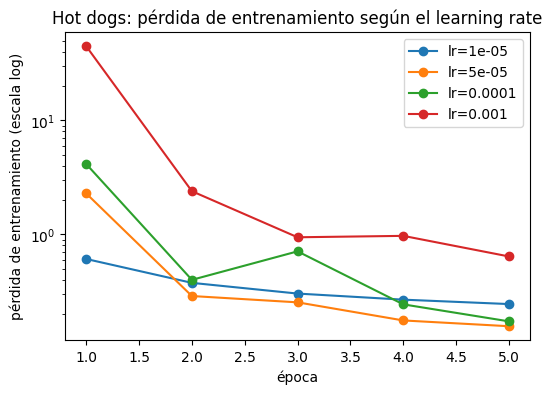

,learning_rate,loss_época_1,loss_final,acc_prueba_final
0,0.00001,0.607,0.244,0.912
1,0.00005,2.285,0.156,0.936
2,0.00010,4.144,0.172,0.940
3,0.00100,44.873,0.639,0.749


In [ ]:
import pandas as pd

plt.figure(figsize=(6, 4))
for lr, h in resultados.items():
    plt.plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], marker="o", label=f"lr={lr}")
plt.yscale("log")
plt.xlabel("época"); plt.ylabel("pérdida de entrenamiento (escala log)")
plt.title("Hot dogs: pérdida de entrenamiento según el learning rate")
plt.legend(); plt.show()

pd.DataFrame({
    "learning_rate": list(resultados.keys()),
    "loss_época_1": [h["train_loss"][0] for h in resultados.values()],
    "loss_final": [h["train_loss"][-1] for h in resultados.values()],
    "acc_prueba_final": [h["eval_acc"][-1] for h in resultados.values()],
}).round({"loss_época_1": 3, "loss_final": 3, "acc_prueba_final": 3})

### **1.2.1 Interpretación de los resultados (Hot Dogs):**

Repetimos el Fine-Tuning del tutorial con cuatro tasas de aprendizaje: `1e-5`, `5e-5` (la del tutorial), `1e-4` y `1e-3`, registrando la pérdida de entrenamiento en cada época (gráfico y tabla de arriba). Cada corrida partió de una copia nueva del modelo preentrenado con una capa `fc` nueva.

**¿Hubo una diferencia significativa?** Sí, pero solo con `1e-3`. Con `1e-5`, `5e-5` y `1e-4` la pérdida final y la precisión en prueba fueron parecidas (pérdida entre 0.15 y 0.25, precisión entre 0.91 y 0.94), y con una sola corrida por valor no podemos decir cuál de las tres es mejor. Con `1e-3` el entrenamiento fue inestable, la pérdida arrancó muy alta, terminó más alta que en las otras y la precisión en prueba fue más baja (cerca de 0.75).

La pérdida de la primera época crece con la tasa de aprendizaje, cuanto mayor es la tasa, más grandes son los pasos de actualización. En el tutorial esos pasos ya son grandes, porque la capa `fc` es nueva y usa una tasa 10 veces mayor, y porque la pérdida se suma sobre las 128 imágenes del lote en lugar de promediarse, lo que agranda el gradiente. Con `1e-5` los pasos son chicos y la pérdida baja de forma estable pero más lenta. Con `5e-5` y `1e-4` el modelo se corrige rápido y llega a buenos resultados en pocas épocas. Con `1e-3` los pasos son tan grandes que probablemente se pierde parte de lo aprendido en ImageNet y el modelo no llega a igualar a los otros en 5 épocas.



---


# **Actividad 2. Aplicación al problema de clasificación de equimosis**

### 2.1 Exploración del Corpus

Se procede a cargar y explorar el conjunto de datos proporcionado por la cátedra para identificar clases, balance, calidad de archivos y variabilidad visual.

Aclaración: Se descomprime `dataset2025_3.zip` la cual contiene moretones y no_moretones.

In [ ]:
from google.colab import drive

drive.mount('/content/drive')
ZIP_PATH = "/content/drive/MyDrive/dataset2025_3.zip"
DATA_DIR = "/content/data_equimosis"

with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall(DATA_DIR)

# Busca la carpeta que contiene las carpetas de clases (por si el zip trae una carpeta intermedia)
RAIZ = None
for root, dirs, _ in os.walk(DATA_DIR):
    if "moretones" in dirs and "no_moretones" in dirs:
        RAIZ = root
        break
print("Carpeta raíz:", RAIZ)

Mounted at /content/drive
Carpeta raíz: /content/data_equimosis/dataset2025_3


Recorre las carpetas de cada clase y arma una tabla con una fila por imagen: si se pudo abrir, su tamaño en píxeles, el peso del archivo, el modo de color, la nitidez, el brillo medio y un hash MD5 para detectar duplicados exactos.

In [ ]:
import hashlib
from PIL import Image
import numpy as np

clases_dir = sorted(d for d in os.listdir(RAIZ) if os.path.isdir(os.path.join(RAIZ, d)))
filas_inv = []
for clase in clases_dir:
    carpeta = os.path.join(RAIZ, clase)
    for f in sorted(os.listdir(carpeta)):
        ruta = os.path.join(carpeta, f)
        fila = {"clase": clase, "archivo": f, "ruta": ruta, "legible": False}
        try:
            with Image.open(ruta) as im:
                im.verify()                                   # detecta archivos corruptos
            with Image.open(ruta) as im:
                fila.update(ancho=im.width, alto=im.height, modo=im.mode)
                g = np.asarray(im.convert("L"), dtype=float)
            lap = (-4 * g[1:-1, 1:-1] + g[:-2, 1:-1] + g[2:, 1:-1]
                   + g[1:-1, :-2] + g[1:-1, 2:])
            fila.update(nitidez=lap.var(), brillo=g.mean(),
                        kb=os.path.getsize(ruta) / 1024,
                        md5=hashlib.md5(open(ruta, "rb").read()).hexdigest(),
                        legible=True)
        except Exception as e:
            fila["error"] = type(e).__name__
        filas_inv.append(fila)
inv = pd.DataFrame(filas_inv)
inv_ok = inv[inv["legible"]]

cuenta = inv["clase"].value_counts()
print("Total de imágenes:", len(inv))
print(cuenta.to_string())
print(f"\nRazón de desbalance: {cuenta.max() / cuenta.min():.2f} : 1")
print("Archivos ilegibles:", int((~inv["legible"]).sum()))
print("\nModos de color por clase:\n", pd.crosstab(inv_ok["clase"], inv_ok["modo"]).to_string())
print("\nTamaño (px), peso (KB), nitidez y brillo por clase:")
print(inv_ok.groupby("clase")[["ancho", "alto", "kb", "nitidez", "brillo"]]
      .agg(["min", "median", "max"]).round(1).T.to_string())
dup = inv_ok[inv_ok.duplicated("md5", keep=False)]
print("\nImágenes en grupos de duplicados exactos:", len(dup), "| grupos:", dup["md5"].nunique())
print("Grupos con la misma imagen en las dos clases:",
      int((dup.groupby("md5")["clase"].nunique() > 1).sum()))

Total de imágenes: 227
clase
moretones       124
no_moretones    103

Razón de desbalance: 1.20 : 1
Archivos ilegibles: 0

Modos de color por clase:
 modo          RGB  RGBA
clase                  
moretones     124     0
no_moretones   99     4

Tamaño (px), peso (KB), nitidez y brillo por clase:
clase           moretones  no_moretones
ancho   min         143.0         144.0
        median      415.5         545.0
        max         640.0        1803.0
alto    min         169.0         157.0
        median      430.5         422.0
        max         640.0        2392.0
kb      min           9.5           9.8
        median       19.9          80.3
        max          93.3         776.5
nitidez min           2.6           5.2
        median       19.6          95.7
        max         575.1        2975.8
brillo  min         102.2          78.1
        median      157.4         147.7
        max         203.5         224.3

Imágenes en grupos de duplicados exactos: 0 | grupos: 0
Grup

Muestra una fila de 6 imágenes al azar por cada clase, para ver a simple vista qué representa cada una y detectar imágenes dudosas.

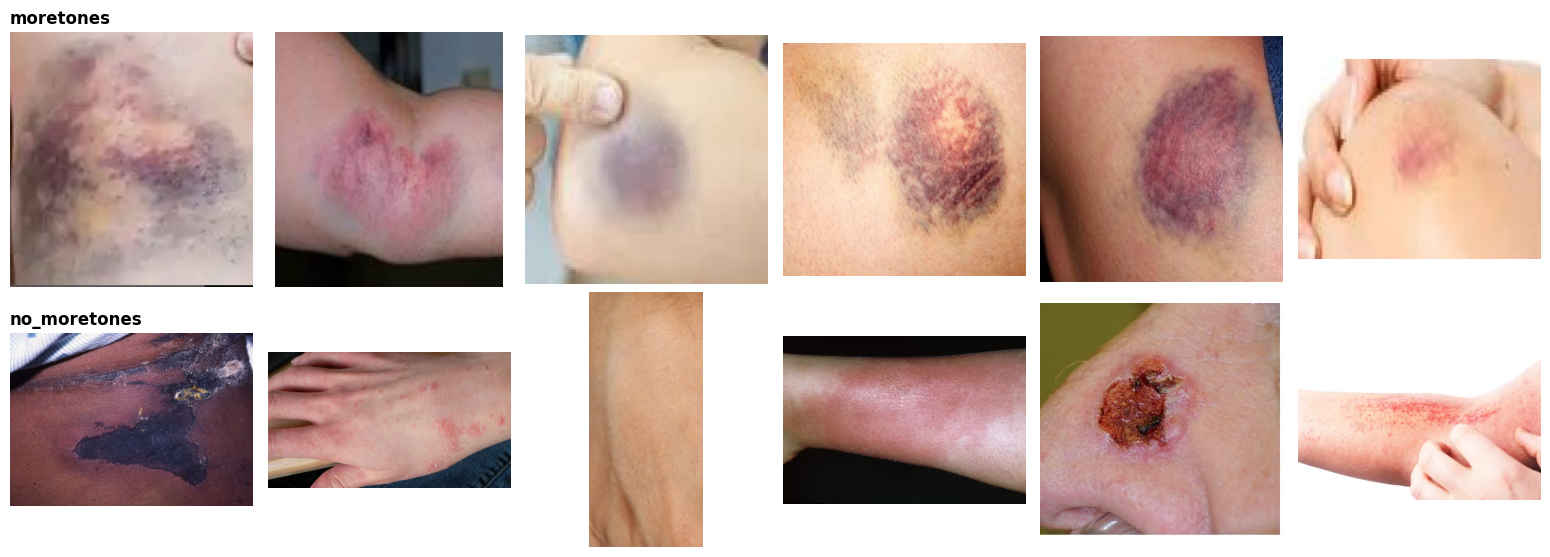

In [ ]:
def mostrar_ejemplos(n=6, seed=0):
    fig, axes = plt.subplots(len(clases_dir), n, figsize=(2.6 * n, 2.8 * len(clases_dir)))
    for i, c in enumerate(clases_dir):
        sub = inv_ok[inv_ok["clase"] == c]
        for j, ruta in enumerate(sub.sample(min(n, len(sub)), random_state=seed)["ruta"]):
            axes[i, j].imshow(Image.open(ruta).convert("RGB"))
            axes[i, j].axis("off")
        axes[i, 0].set_title(c, loc="left", fontweight="bold")
    plt.tight_layout(); plt.show()

mostrar_ejemplos()

###**2.1.1 Identificar las clases disponibles y explicar qué representa cada una**

Las clases disponibles son `moretones` y `no_moretones`. La primera representa imágenes de piel con un moretón (equimosis). La segunda representa imágenes de piel sin moretón, que incluyen piel sana y también otras lesiones o alteraciones de la piel (heridas, rasguños, enrojecimientos o manchas rojas).

### **2.1.2 Informar la cantidad total de imágenes y la cantidad de imágenes por clase**

Se cuenta con:
* 124 imagenes de moretones
* 103 imagenes de no moretones

En total: 227 imagenes.

### **2.1.3 Visualizar ejemplos de imágenes de cada clase**

En la fila de `moretones` se ven hematomas de distintos colores (violáceos, rojizos, azulados), en distintas partes del cuerpo, casi siempre ocupando gran parte de la imagen; alguno es muy tenue. En la fila de `no_moretones` hay piel sin lesiones, pero también otras alteraciones que no son moretones sino heridas, rasguños, enrojecimientos y manchas rojas. Los ejemplos se eligen al azar, así que no son una descripción exhaustiva del corpus.

### **2.1.4 ¿Existe un desbalance entre las clases? Identificar problemasen los datos**
Hay un desbalance leve: 124 imágenes de moretones y 103 de no moretones.

**Problemas detectados en los datos**

- **Archivos ilegibles:** ninguno.
- **Imágenes repetidas:** no hay duplicados exactos (comparamos el contenido de los archivos).
- **Modo de color:** casi todas son RGB, salvo 4 imágenes de `no_moretones` con canal de transparencia (RGBA). `ImageFolder` las abre como RGB, así que no dan problemas.
- **Tamaño y calidad:** el tamaño varía mucho, desde unos 150 píxeles hasta más de 2000 de lado. Entre clases, las imágenes de `no_moretones` llegan a tamaños mucho mayores, pesan bastante más y son en general más nítidas, mientras que las de moretones no superan los 640 píxeles. El brillo medio es parecido en ambas.

Como todas las imágenes se redimensionan a 224×224, la diferencia de tamaño pierde importancia.

### **2.1.5 Descripción del corpus**

El corpus tiene 227 imágenes en dos clases: `moretones` (124), con imágenes de piel con un moretón, y `no_moretones` (103), con imágenes de piel sin moretón, que incluye piel sana y otras lesiones. Es un corpus chico y levemente desbalanceado, sin archivos ilegibles ni duplicados exactos, y con imágenes muy heterogéneas en tamaño y calidad, con diferencias entre las clases. Se dividió en 158 imágenes de entrenamiento, 34 de validación y 35 de prueba.

## **2.2 Adaptación del modelo y 2.3 Expertimentos**

**Experimentos a realizar:**
1. **Experimento 1 (Fine-Tuning Base):** Entrenarmos una ResNet-18 (preentrenada en ImageNet1K_V1) adaptando su capa `fc` a 2 salidas, con la tasa original de `5e-5`.
2. **Experimento 2 (Variación de LR):** Repetimos el experimento modificando la tasa de aprendizaje (`1e-5`, `1e-4` y `1e-3`).

 Aclaración: Todos los parámetros del entrenamiento. La normalización usa la media y desviación de ImageNet porque ResNet-18 fue preentrenada con esos valores.

In [ ]:
import random

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_EPOCHS = 10
LEARNING_RATE = 5e-5
PROP_TRAIN, PROP_VAL, PROP_TEST = 0.70, 0.15, 0.15
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DEVICE)

Dispositivo: cuda


En entrenamiento usamos solo transformaciones geométricas: recorte aleatorio y espejado horizontal. Ninguna altera el color, que es la característica visual clave de una equimosis, y el espejado no cambia el aspecto de la lesión. No usamos variaciones de brillo, contraste, saturación ni tono. En validación y prueba solo se redimensiona, se recorta el centro y se normaliza. La normalización usa la media y desviación de ImageNet, porque ResNet-18 fue preentrenada con esos valores. Limitamos el recorte al 70 % del área (el tutorial usa un valor por defecto mucho menor) para que no deje la lesión fuera de la imagen.

In [ ]:
import torchvision
from torchvision import transforms

transform_train = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
transform_eval = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

Divide el corpus en 70 % entrenamiento, 15 % validación y 15 % prueba, manteniendo en cada parte la misma proporción de cada clase.


El entrenamiento ajusta los pesos, la validación permite seguir cómo aprende el modelo en cada época y comparar tasas de aprendizaje, y la prueba se usa al final para evaluar los modelos entrenados.

In [ ]:
from torch.utils.data import Subset, DataLoader
from sklearn.model_selection import train_test_split

base = torchvision.datasets.ImageFolder(RAIZ)
clases = base.classes
targets = np.array(base.targets)
idx = np.arange(len(base))

idx_trainval, idx_test = train_test_split(
    idx, test_size=PROP_TEST, stratify=targets, random_state=SEED)
idx_train, idx_val = train_test_split(
    idx_trainval, test_size=PROP_VAL / (PROP_TRAIN + PROP_VAL),
    stratify=targets[idx_trainval], random_state=SEED)

# Dos copias del dataset: una con aumento (train) y otra sin aumento (val/test)
ds_train = Subset(torchvision.datasets.ImageFolder(RAIZ, transform=transform_train), idx_train)
ds_val   = Subset(torchvision.datasets.ImageFolder(RAIZ, transform=transform_eval),  idx_val)
ds_test  = Subset(torchvision.datasets.ImageFolder(RAIZ, transform=transform_eval),  idx_test)

train_iter = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_iter   = DataLoader(ds_val,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_iter  = DataLoader(ds_test,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("Clases:", clases, "->", base.class_to_idx)
for nombre, ix in [("train", idx_train), ("val", idx_val), ("test", idx_test)]:
    cuenta = np.bincount(targets[ix], minlength=len(clases)).tolist()
    print(f"{nombre:5s}: {len(ix):4d} imágenes  {dict(zip(clases, cuenta))}")

Clases: ['moretones', 'no_moretones'] -> {'moretones': 0, 'no_moretones': 1}
train:  158 imágenes  {'moretones': 86, 'no_moretones': 72}
val  :   34 imágenes  {'moretones': 19, 'no_moretones': 15}
test :   35 imágenes  {'moretones': 19, 'no_moretones': 16}


Carga ResNet-18 con los pesos preentrenados de ImageNet y reemplaza la última capa (fc, que tenía 1000 salidas) por una nueva con tantas salidas como clases del corpus (2: moretones y no_moretones). Solo esa capa nueva empieza con pesos aleatorios. Todo el resto de la red conserva lo aprendido en ImageNet.

In [ ]:
def crear_modelo(num_clases):
    net = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
    net.fc = nn.Linear(net.fc.in_features, num_clases)   # 512 -> num_clases
    nn.init.xavier_uniform_(net.fc.weight)
    return net

NUM_CLASES = len(clases)
modelo = crear_modelo(NUM_CLASES).to(DEVICE)
print("Salidas de la capa fc:", modelo.fc.out_features)

Salidas de la capa fc: 2


**Experimento 1:** Fine-Tuning de ResNet-18 preentrenada con la capa fc nueva de 2 salidas, entrenando con el conjunto de entrenamiento y midiendo la validación en cada época. Se guarda el historial y el modelo entrenado para evaluarlo después en prueba.

In [ ]:
resultados_eq, modelos_eq = {}, {}

torch.manual_seed(SEED)
modelos_eq[LEARNING_RATE] = crear_modelo(NUM_CLASES)
resultados_eq[LEARNING_RATE] = train_registrando(
    modelos_eq[LEARNING_RATE], train_iter, val_iter, LEARNING_RATE, NUM_EPOCHS)

epoch 1, loss 0.954530, acc 0.557, eval_loss 0.853633, eval_acc 0.529
epoch 2, loss 0.632800, acc 0.734, eval_loss 0.410371, eval_acc 0.735
epoch 3, loss 0.271253, acc 0.892, eval_loss 0.315461, eval_acc 0.824
epoch 4, loss 0.197376, acc 0.911, eval_loss 0.323514, eval_acc 0.824
epoch 5, loss 0.135868, acc 0.968, eval_loss 0.265255, eval_acc 0.853
epoch 6, loss 0.179309, acc 0.924, eval_loss 0.235132, eval_acc 0.882
epoch 7, loss 0.136088, acc 0.968, eval_loss 0.225576, eval_acc 0.853
epoch 8, loss 0.157454, acc 0.918, eval_loss 0.439514, eval_acc 0.794
epoch 9, loss 0.187329, acc 0.930, eval_loss 0.215636, eval_acc 0.882
epoch 10, loss 0.101130, acc 0.981, eval_loss 0.321242, eval_acc 0.824


**Experimento 2:** Repite el entrenamiento cambiando solo la tasa de aprendizaje. Cada corrida arranca desde un modelo preentrenado nuevo y la misma semilla.

In [ ]:
for lr in [1e-5, 1e-4, 1e-3]:
    print(f"\n=== learning rate = {lr} ===")
    torch.manual_seed(SEED)
    modelos_eq[lr] = crear_modelo(NUM_CLASES)
    resultados_eq[lr] = train_registrando(modelos_eq[lr], train_iter, val_iter, lr, NUM_EPOCHS)


=== learning rate = 1e-05 ===
epoch 1, loss 0.959886, acc 0.481, eval_loss 0.612215, eval_acc 0.618
epoch 2, loss 0.696885, acc 0.633, eval_loss 0.538374, eval_acc 0.676
epoch 3, loss 0.617980, acc 0.658, eval_loss 0.506327, eval_acc 0.676
epoch 4, loss 0.499177, acc 0.766, eval_loss 0.485913, eval_acc 0.676
epoch 5, loss 0.415045, acc 0.823, eval_loss 0.452885, eval_acc 0.735
epoch 6, loss 0.453656, acc 0.753, eval_loss 0.432154, eval_acc 0.765
epoch 7, loss 0.382935, acc 0.816, eval_loss 0.409024, eval_acc 0.765
epoch 8, loss 0.361875, acc 0.842, eval_loss 0.418453, eval_acc 0.765
epoch 9, loss 0.350864, acc 0.867, eval_loss 0.397349, eval_acc 0.794
epoch 10, loss 0.323744, acc 0.848, eval_loss 0.402933, eval_acc 0.794

=== learning rate = 0.0001 ===
epoch 1, loss 1.036525, acc 0.665, eval_loss 0.373278, eval_acc 0.794
epoch 2, loss 0.392713, acc 0.804, eval_loss 0.509069, eval_acc 0.765
epoch 3, loss 0.431669, acc 0.772, eval_loss 0.228738, eval_acc 0.853
epoch 4, loss 0.115672, ac

Compara cómo evoluciona la pérdida con cada tasa, en entrenamiento y en validación (escala logarítmica).

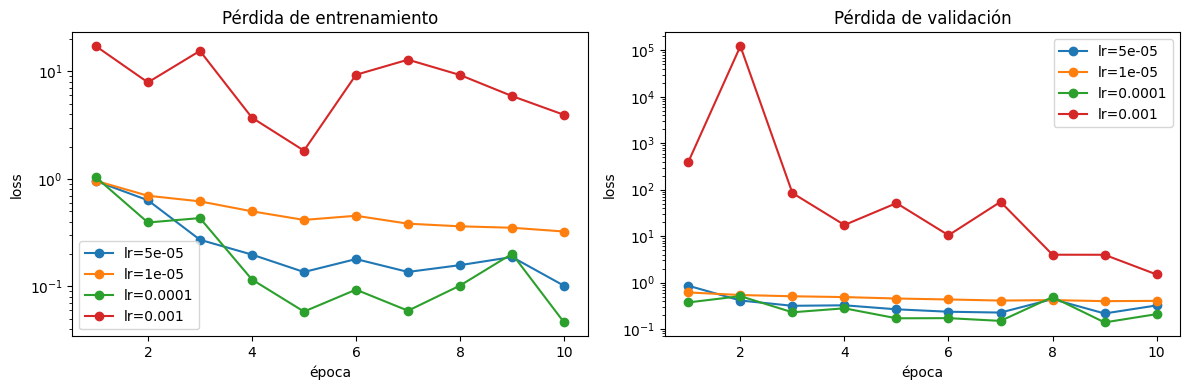

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for lr, h in resultados_eq.items():
    ep = range(1, len(h["train_loss"]) + 1)
    ax[0].plot(ep, h["train_loss"], marker="o", label=f"lr={lr}")
    ax[1].plot(ep, h["eval_loss"], marker="o", label=f"lr={lr}")
for a, t in zip(ax, ["Pérdida de entrenamiento", "Pérdida de validación"]):
    a.set(title=t, xlabel="época", ylabel="loss", yscale="log"); a.legend()
plt.tight_layout(); plt.show()

Evalúa cada modelo entrenado con el conjunto de prueba. La tabla muestra la precisión global y la precision, el recall y el F1 de cada clase. Las matrices de confusión muestran cuántas imágenes de cada clase real se clasificaron en cada clase predicha: la diagonal son los aciertos y fuera de ella están las confusiones.

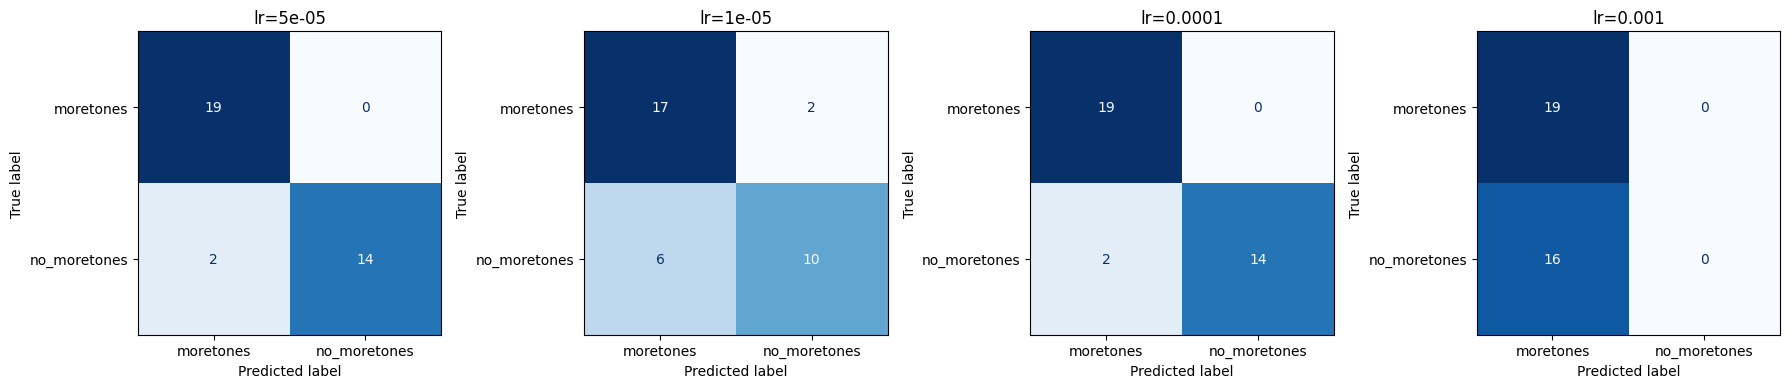

,learning_rate,acc_prueba,precision_moretones,recall_moretones,f1_moretones,precision_no_moretones,recall_no_moretones,f1_no_moretones
0,0.00005,0.943,0.905,1.000,0.950,1.000,0.875,0.933
1,0.00001,0.771,0.739,0.895,0.810,0.833,0.625,0.714
2,0.00010,0.943,0.905,1.000,0.950,1.000,0.875,0.933
3,0.00100,0.543,0.543,1.000,0.704,0.000,0.000,0.000


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

def evaluar(net, loader):
    net.eval()
    y_real, y_pred = [], []
    with torch.no_grad():
        for X, y in loader:
            y_pred += net(X.to(DEVICE)).argmax(1).cpu().tolist()
            y_real += y.tolist()
    return y_real, y_pred

filas = []
fig, axes = plt.subplots(1, len(modelos_eq), figsize=(4.5 * len(modelos_eq), 4))
for ax, (lr, net) in zip(axes, modelos_eq.items()):
    y_real, y_pred = evaluar(net, test_iter)
    rep = classification_report(y_real, y_pred, target_names=clases,
                                output_dict=True, zero_division=0)
    fila = {"learning_rate": lr, "acc_prueba": rep["accuracy"]}
    for c in clases:
        fila[f"precision_{c}"] = rep[c]["precision"]
        fila[f"recall_{c}"] = rep[c]["recall"]
        fila[f"f1_{c}"] = rep[c]["f1-score"]
    filas.append(fila)
    ConfusionMatrixDisplay(confusion_matrix(y_real, y_pred), display_labels=clases
                           ).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"lr={lr}")
plt.tight_layout(); plt.show()
tabla = pd.DataFrame(filas)
tabla.round({c: 3 for c in tabla.columns if c != "learning_rate"})

In [ ]:
params = {
    "Modelo": "ResNet-18 preentrenada (ImageNet1K_V1)",
    "Salidas de la capa fc": NUM_CLASES,
    "Clases": ", ".join(clases),
    "Tamaño de entrada": f"{IMG_SIZE}x{IMG_SIZE}",
    "Normalización": "media y desviación de ImageNet",
    "Aumento (train)": "RandomResizedCrop(scale 0.7-1.0) + flip horizontal (sin cambios de color)",
    "Partición train/val/test": f"{PROP_TRAIN}/{PROP_VAL}/{PROP_TEST} (estratificada)",
    "Imágenes train/val/test": f"{len(idx_train)}/{len(idx_val)}/{len(idx_test)}",
    "Optimizador": "SGD",
    "Learning rate Exp. 1 (capas preentrenadas / fc)": f"{LEARNING_RATE} / {LEARNING_RATE * 10}",
    "Learning rates Exp. 2": "1e-5, 1e-4, 1e-3 (fc = 10x)",
    "Weight decay": 0.001,
    "Batch size": BATCH_SIZE,
    "Épocas": NUM_EPOCHS,
    "Función de pérdida": "CrossEntropyLoss (suma por lote, como el tutorial)",
    "Semilla": SEED,
}
pd.Series(params, name="valor").to_frame()

,valor
Modelo,ResNet-18 preentrenada (ImageNet1K_V1)
Salidas de la capa fc,2
Clases,"moretones, no_moretones"
Tamaño de entrada,224x224
Normalización,media y desviación de ImageNet
Aumento (train),RandomResizedCrop(scale 0.7-1.0) + flip horizo...
Partición train/val/test,0.7/0.15/0.15 (estratificada)
Imágenes train/val/test,158/34/35
Optimizador,SGD
Learning rate Exp. 1 (capas preentrenadas / fc),5e-05 / 0.0005


### **2.4 Análisis de resultados**

**1. ¿Qué resultados se obtuvieron para cada clase?**
Con 5e-5 y 1e-4 se obtuvieron los mejores resultados, muy parecidos entre sí, con una precisión en prueba cercana a 0.94. En ambos casos el modelo detectó todos los moretones del conjunto de prueba (recall máximo para `moretones`) y su error estuvo en la otra clase: algunas imágenes `no_moretones` se clasificaron como `moretones`, por lo que `no_moretones` tuvo menor recall y `moretones` menor precision. Con 1e-5 los resultados fueron bastante peores en las dos clases, y con 1e-3 el modelo no aprendió a distinguirlas.

**2. ¿Existen clases que el modelo confunde frecuentemente?**
Con 5e-5 y 1e-4 hay pocas confusiones y van en un solo sentido, de `no_moretones` hacia `moretones`. Con 1e-5 las confusiones aparecen en ambos sentidos, y son más frecuentes de `no_moretones` a `moretones`. Con 1e-3 no hay una confusión entre clases sino un colapso, el modelo clasifica todas las imágenes como `moretones`, por lo que acierta solo en la proporción que esa clase ocupa en el conjunto de prueba.

**3. ¿Cómo influye la tasa de aprendizaje en los resultados?**
Influye mucho en los extremos y poco en el medio. Con 1e-5 la tasa es demasiado chica, la pérdida baja muy lento y en 10 épocas el modelo queda sin terminar de entrenar. Con 5e-5 y 1e-4 el modelo aprende bien y llega a buenos resultados, sin una diferencia clara entre ambas. Con 1e-3 el entrenamiento se vuelve inestable, la pérdida se mantiene alta y llega a valores enormes en validación, y el modelo se queda en un nivel cercano al azar.

Igual que en hot dogs, una tasa demasiado alta desestabiliza el entrenamiento, aunque acá el efecto fue más grave. Con 1e-5 también se ve una diferencia con hot dogs, donde esa tasa funcionó bastante mejor. Una posible explicación es que este corpus tiene pocas imágenes y, por lo tanto, pocas actualizaciones de los pesos en 10 épocas.

**4. ¿Qué dificultades presenta la clasificación de las imágenes de este corpus?**
La principal es que el corpus es muy chico: 227 imágenes, de las cuales solo 158 se usan para entrenar. Los conjuntos de validación y de prueba son todavía más chicos (unas 35 imágenes cada uno), por lo que cada imagen pesa mucho en el resultado y las métricas son inestables. Además, la clase `no_moretones` no es solo piel sana, sino que incluye heridas, rasguños y enrojecimientos que pueden parecerse a un moretón.

**5. ¿Qué ventajas y limitaciones presenta utilizar una red preentrenada con ImageNet para esta tarea?**
La ventaja es que las características generales (bordes, texturas, colores) ya vienen aprendidas, por eso con pocas imágenes y pocas épocas se llegó a buenos resultados. Con tan pocos datos, entrenar desde cero sería mucho más difícil. Las limitaciones son que ImageNet no contiene imágenes médicas ni de lesiones en la piel, por lo que hay una diferencia con este corpus, que el resultado es sensible a la tasa de aprendizaje (con 1e-3 se perdió todo), y que, con un conjunto de prueba tan chico, no se puede asegurar que el desempeño se mantenga con imágenes nuevas.